# Experiment 4: Steel-Plant Energy EDA

This notebook uses the supplied `Steel_industry_data 3.csv` (35,040 actual readings), creates reproducible plots and statistical observations, and writes figures/reports to `outputs/`. The target is `Usage_kWh`; `Load_Type` is a feature in this regression project.

EDA informs a chronological split, time/calendar and lag features, a persistence baseline, and error checks by operating load. Outliers are inspected, not automatically removed.

In [1]:
from pathlib import Path
from IPython.display import Image, display
import pandas as pd
from steel_energy.eda import run_eda
from steel_energy.config import FIGURE_DIR, RAW_DATA_PATH

report = run_eda()
print(f"Loaded: {RAW_DATA_PATH}")
print(f"Rows: {len(pd.read_csv(RAW_DATA_PATH)):,}")
for insight in report["insights"]:
    print("-", insight)

Loaded: Steel_industry_data 3.csv
Rows: 35,040
- Usage_kWh has skewness 1.20; the distribution is right-skewed relative to a symmetric distribution.
- Mean usage is 27.39 kWh per interval and median is 4.57 kWh, indicating that the median is a useful robust reference.
- Weekend mean usage is 11.73 kWh and weekday mean usage is 33.62 kWh.
- Maximum_Load has the highest average usage (59.27 kWh per interval) among the recorded load types.
- Monthly average usage is highest in January (42.42 kWh) and lowest in December (19.97 kWh); one year cannot establish a recurring annual season.
- `CO2(tCO2)` has the largest absolute Pearson correlation with Usage_kWh among the numeric source features (r=0.988).
- Autocorrelation is 0.912 at 15 minutes and 0.606 at 24 hours, supporting chronological lag features.
- About 0.9% of target readings lie outside the 1.5-IQR whiskers; inspect these operating peaks rather than deleting them automatically.


## Target distribution and descriptive statistics

The target is strongly right-skewed if its mean is above its median and skewness is positive. MAPE in later experiments excludes zero actual readings and reports their count.

In [2]:
data = pd.read_csv(RAW_DATA_PATH, encoding="utf-8-sig")
target = data["Usage_kWh"]
display(target.describe().to_frame("Usage_kWh"))
print({"skewness": target.skew(), "zero_readings": int((target == 0).sum()), "outlier_share_1_5_IQR": report["iqr_outlier_share"]})
display(data.groupby("Load_Type")["Usage_kWh"].agg(["count", "mean", "median", "std"]))

,Usage_kWh
count,35040.000000
mean,27.386892
std,33.444380
min,0.000000
25%,3.200000
50%,4.570000
75%,51.237500
max,157.180000


{'skewness': 1.197393822769221, 'zero_readings': 1, 'outlier_share_1_5_IQR': 0.009360730593607305}


,count,mean,median,std
Load_Type,,,,
Light_Load,18072,8.626207,3.310,17.906245
Maximum_Load,7272,59.265314,56.630,29.749700
Medium_Load,9696,38.445394,34.435,35.220166


## Time-series and daily/weekly patterns

Daily totals show longer trends; interval means by hour and weekday expose recurring scheduling patterns. Monthly means are shown for within-year seasonality, but one year cannot prove an annual recurring pattern.

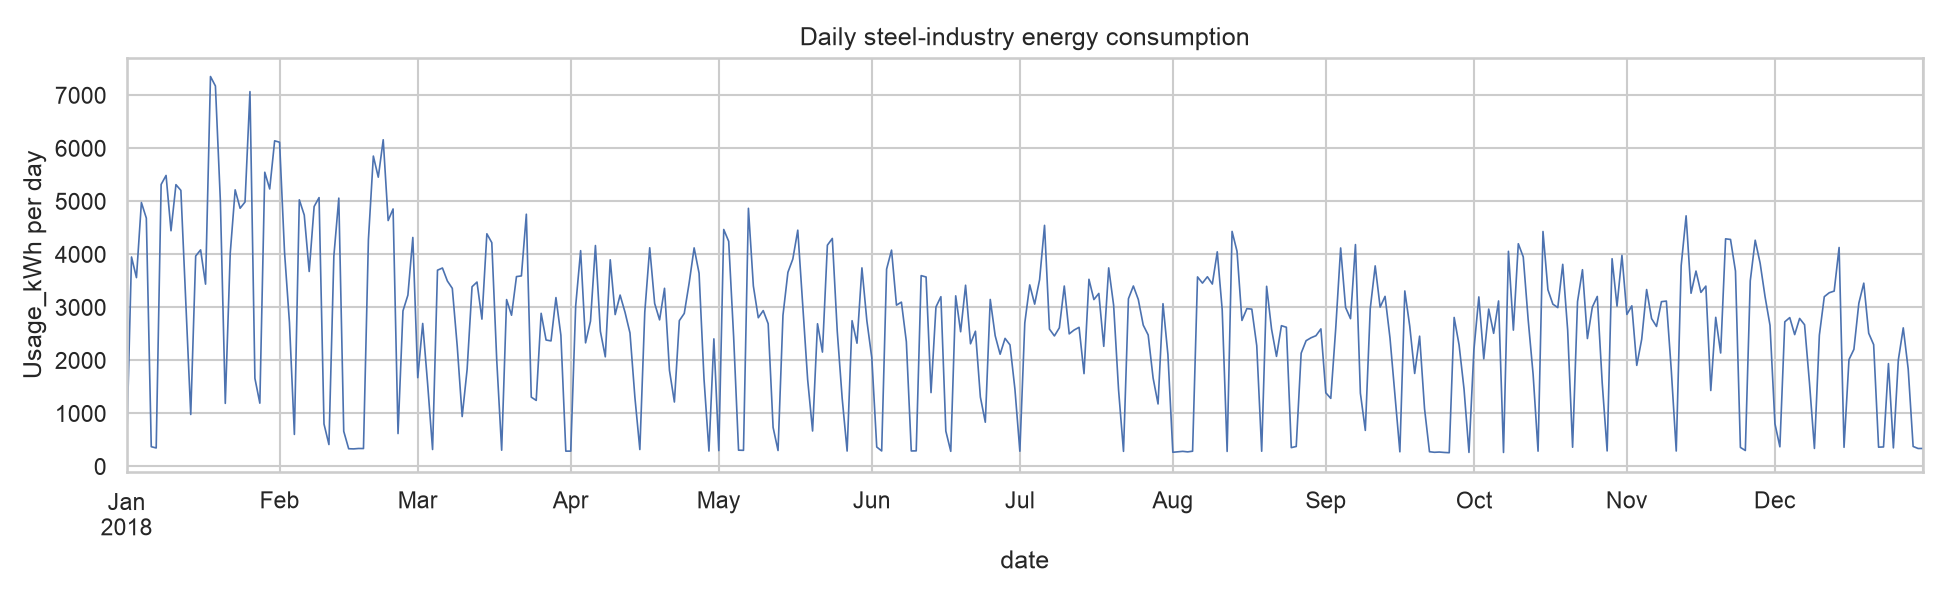

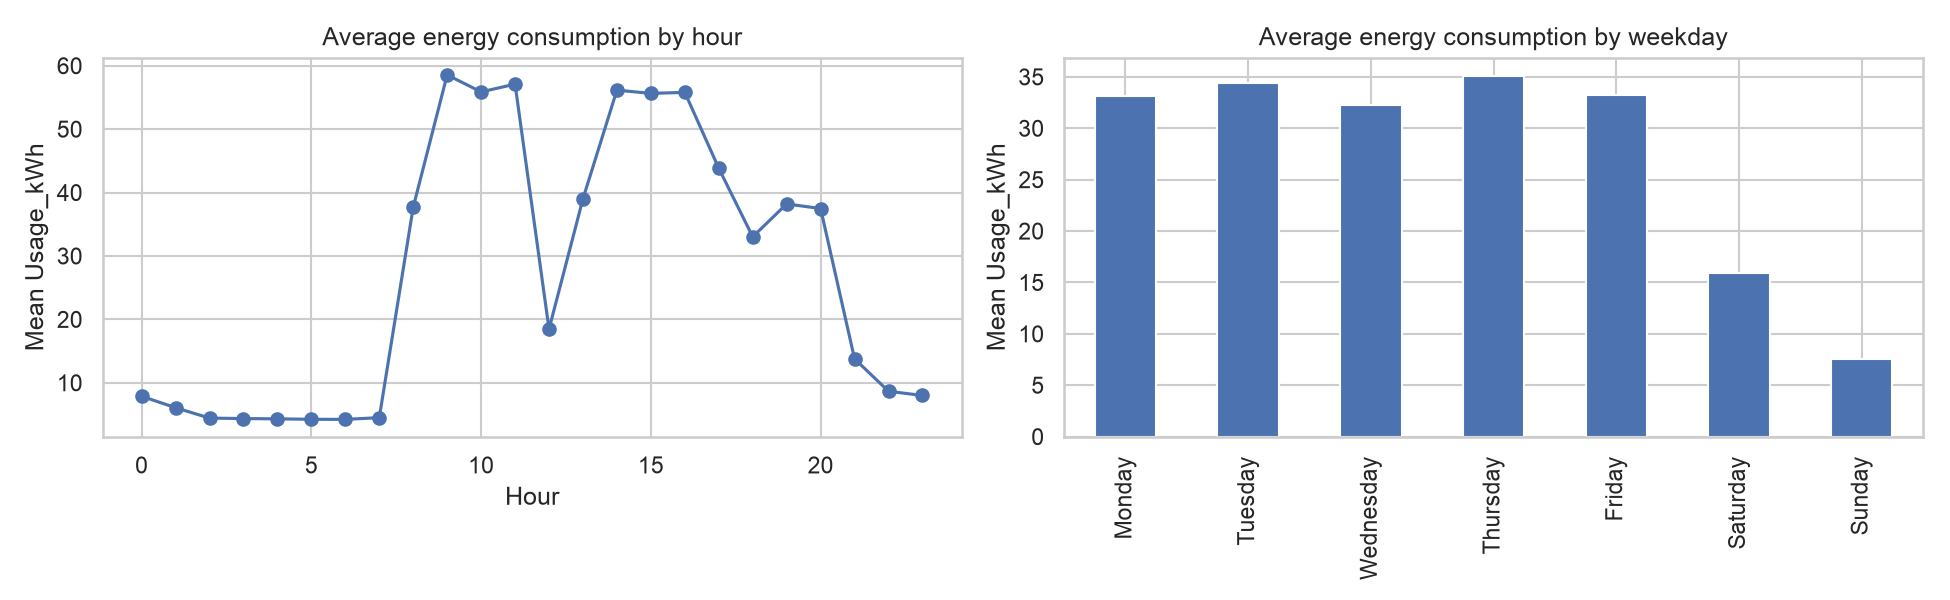

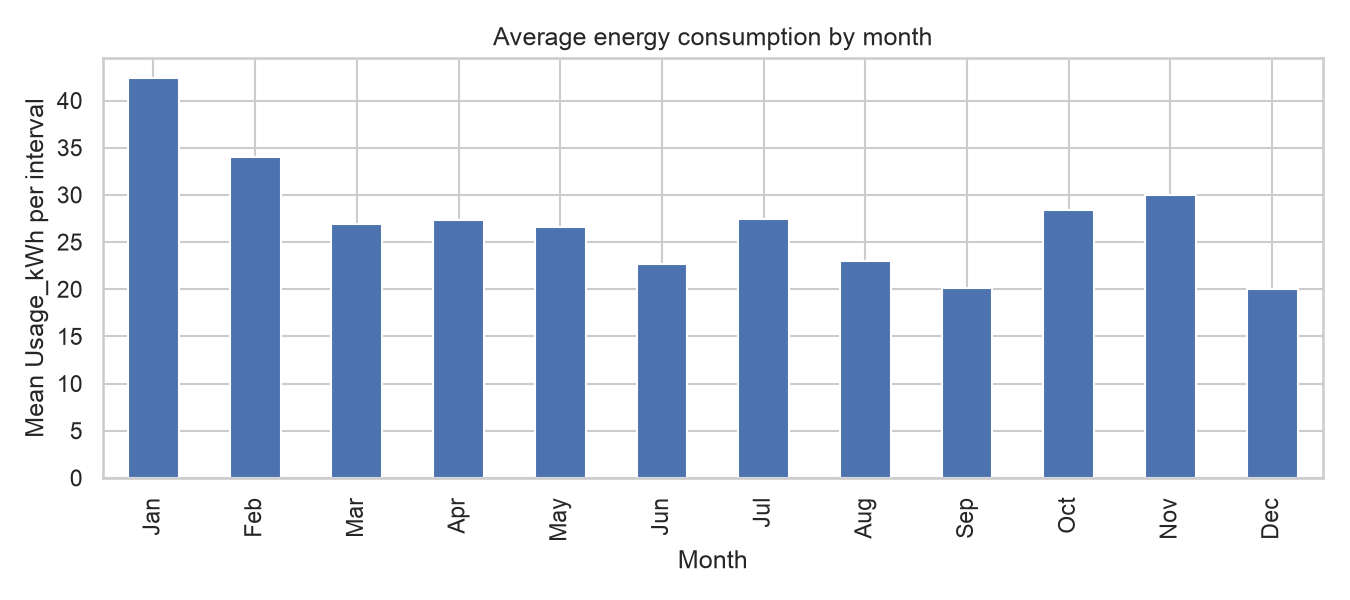

In [3]:
display(Image(filename=str(FIGURE_DIR / "consumption_timeseries.png")))
display(Image(filename=str(FIGURE_DIR / "daily_weekly_patterns.png")))
display(Image(filename=str(FIGURE_DIR / "monthly_seasonality.png")))

## Distribution and load-type differences

The box plot compares operating regimes. Large group differences suggest retaining `Load_Type`; extreme readings should be investigated as real process events rather than discarded solely as statistical outliers.

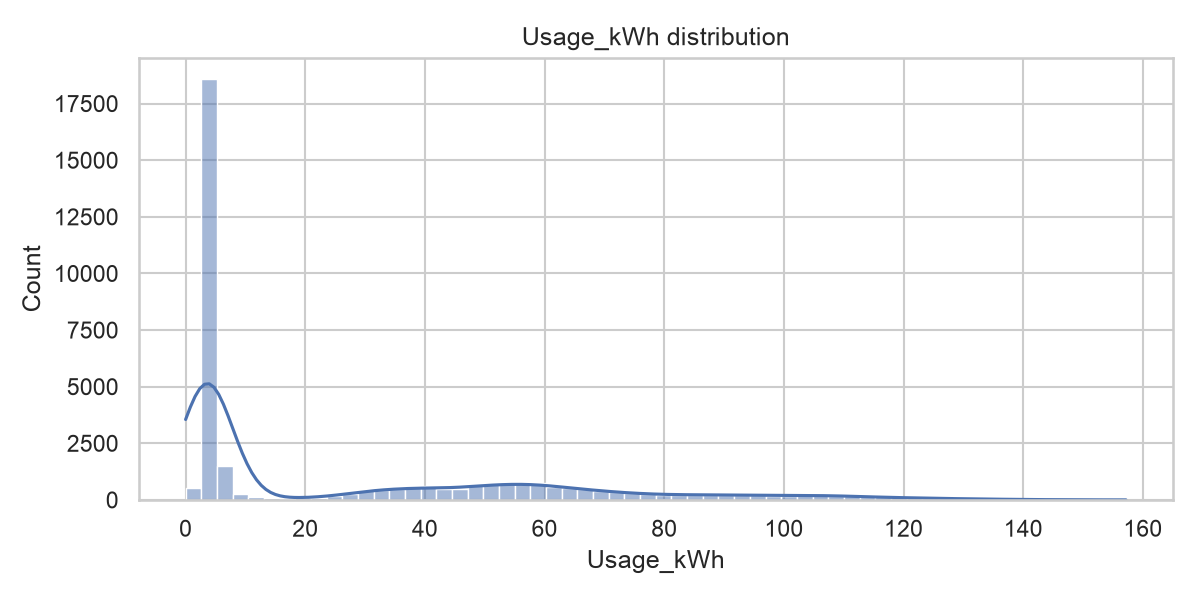

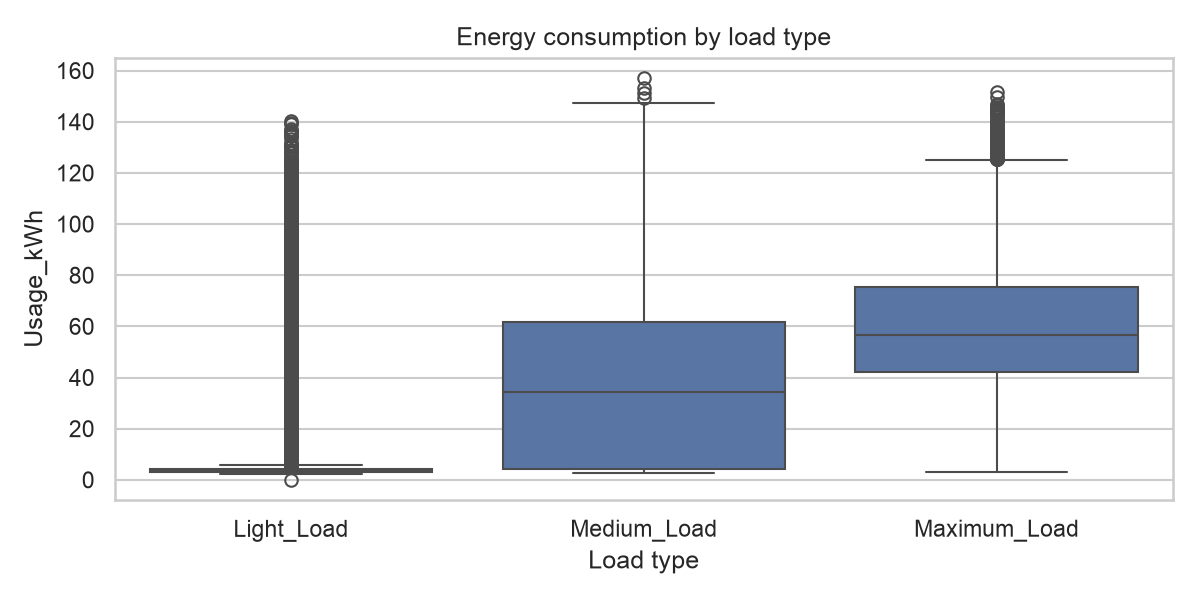

In [4]:
display(Image(filename=str(FIGURE_DIR / "target_distribution.png")))
display(Image(filename=str(FIGURE_DIR / "load_type_comparison.png")))

## Power-factor and correlation analysis

Pearson correlations describe linear association, not causality. They help flag redundant features and candidate predictors but tree models can still use nonlinear interactions.

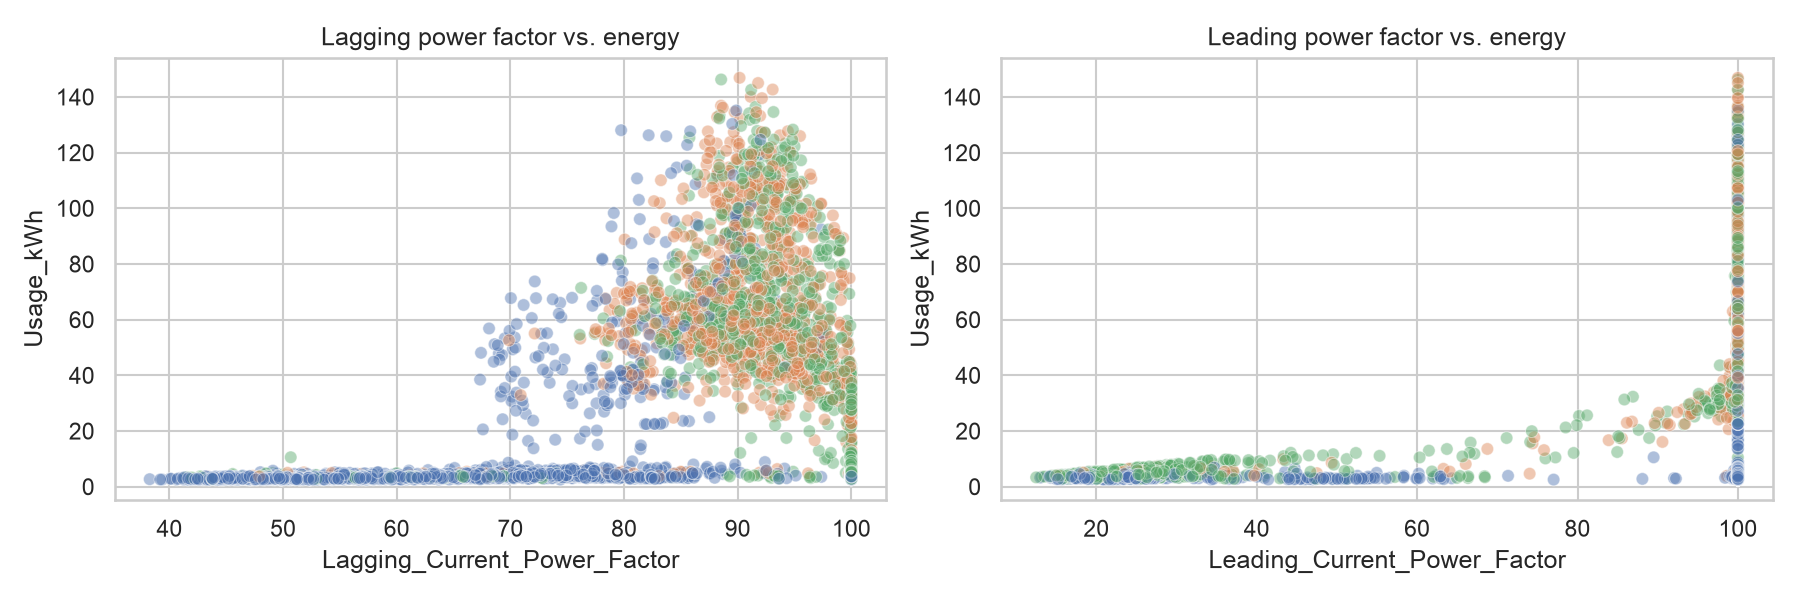

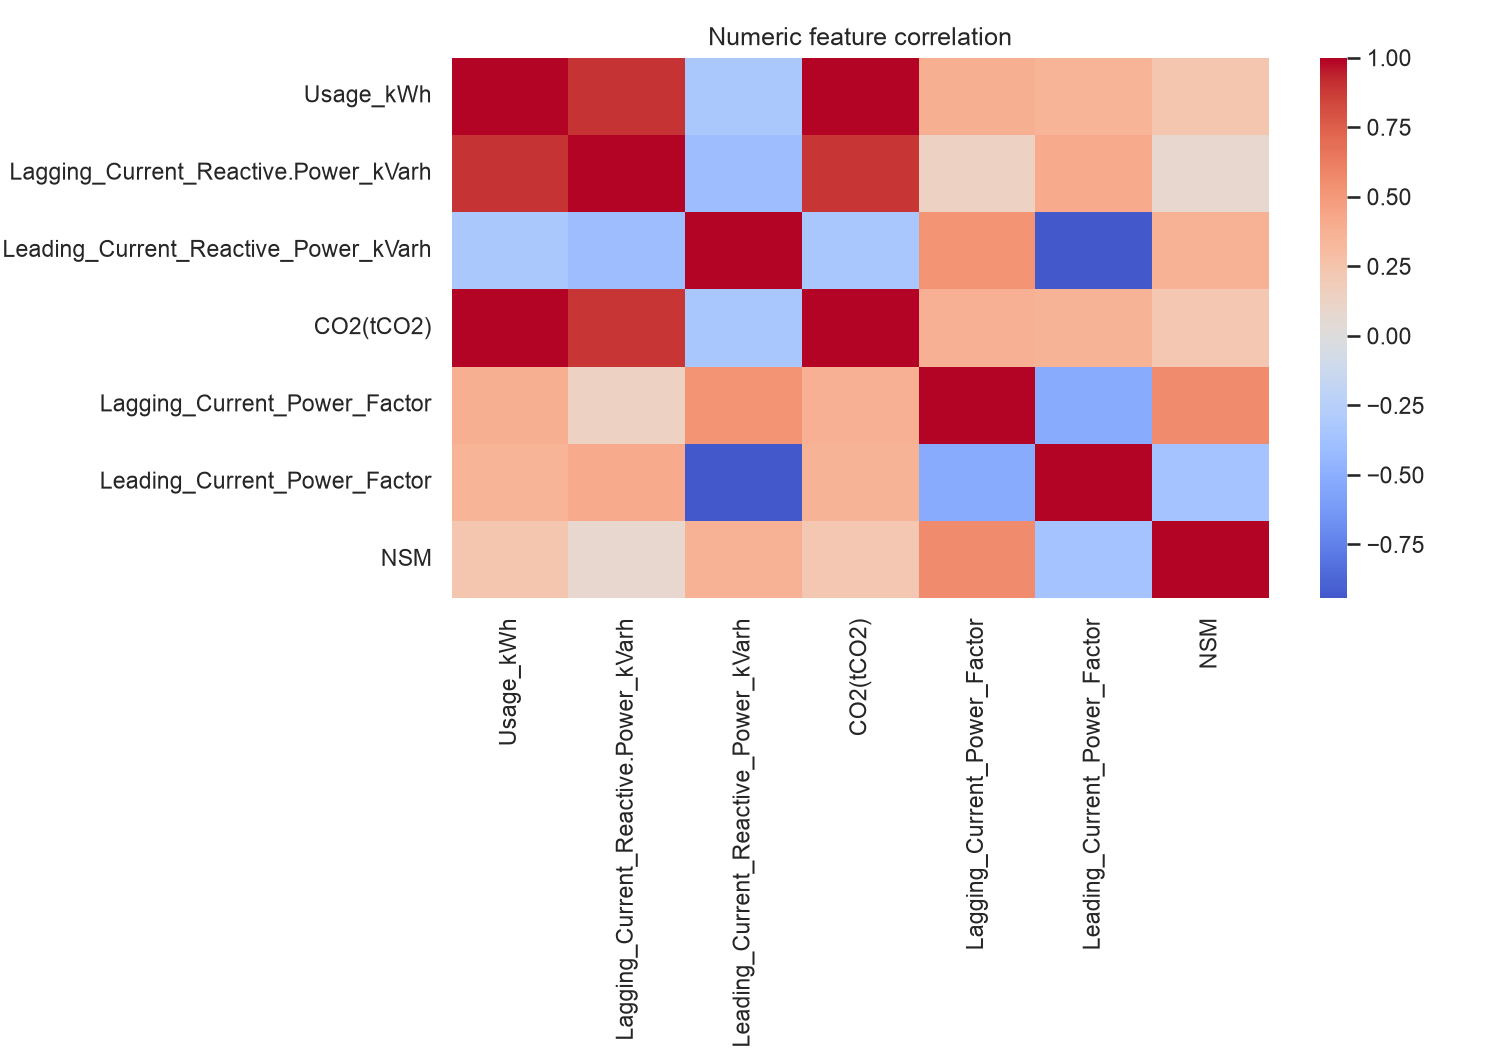

,Pearson correlation with Usage_kWh
CO2(tCO2),0.988180
Lagging_Current_Reactive.Power_kVarh,0.896150
Lagging_Current_Power_Factor,0.385960
Leading_Current_Power_Factor,0.353566
Leading_Current_Reactive_Power_kVarh,-0.324922
NSM,0.234610


In [5]:
display(Image(filename=str(FIGURE_DIR / "power_factor_relationships.png")))
display(Image(filename=str(FIGURE_DIR / "correlation_heatmap.png")))
display(pd.Series(report["target_correlations"], name="Pearson correlation with Usage_kWh").to_frame())

## Lag relationships and model implications

Lag-1 is the last observed 15-minute value, lag-4 is one hour, lag-96 is one day, and lag-672 is one week. The modeling pipeline shifts all target history before constructing predictors to avoid leakage. Validation and test partitions are future periods; they are never randomly shuffled.

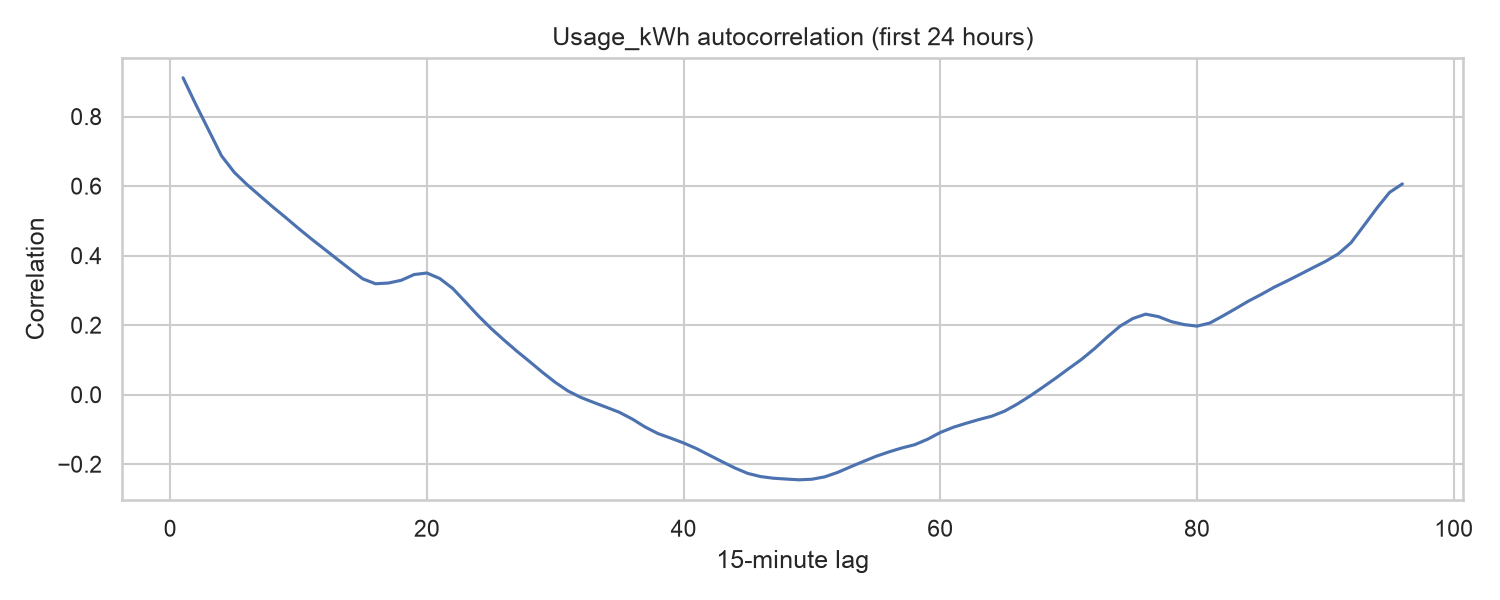

Selected lag correlations: {'1': 0.9115459739383571, '4': 0.6867864545079121, '96': 0.6062959009726046, '672': 0.676702943038885}

Seven observations:
1. Usage_kWh has skewness 1.20; the distribution is right-skewed relative to a symmetric distribution.
2. Mean usage is 27.39 kWh per interval and median is 4.57 kWh, indicating that the median is a useful robust reference.
3. Weekend mean usage is 11.73 kWh and weekday mean usage is 33.62 kWh.
4. Maximum_Load has the highest average usage (59.27 kWh per interval) among the recorded load types.
5. Monthly average usage is highest in January (42.42 kWh) and lowest in December (19.97 kWh); one year cannot establish a recurring annual season.
6. `CO2(tCO2)` has the largest absolute Pearson correlation with Usage_kWh among the numeric source features (r=0.988).
7. Autocorrelation is 0.912 at 15 minutes and 0.606 at 24 hours, supporting chronological lag features.
8. About 0.9% of target readings lie outside the 1.5-IQR whiskers; inspect thes

In [6]:
display(Image(filename=str(FIGURE_DIR / "autocorrelation.png")))
print("Selected lag correlations:", report["autocorrelations"])
print("\nSeven observations:")
print("\n".join(f"{i}. {item}" for i, item in enumerate(report["insights"], 1)))

## EDA conclusions

1. The target's distribution, mean/median gap, and IQR outlier rate motivate robust error review and retaining process peaks.
2. Hour/day-of-week patterns motivate calendar predictors, subject to future-period validation.
3. Load-type group differences support using `Load_Type` when it is available at forecast time.
4. Power-factor and reactive-power plots motivate including these sensor readings. CO2 is very strongly correlated with Usage_kWh and is excluded from model predictors because its timing could leak same-interval energy use.
5. Autocorrelation motivates shifted usage lags and comparison with the last-value persistence baseline.
6. Monthly means expose possible within-year variation, but one year cannot establish recurring annual seasonality.
7. No random split is used: future data must remain unseen during fitting and model choice.